# Multiple Object Video Detection
## Two-stage anchor based (FasterCNN)

Downloading scripts and chepoints fro google drive

In [1]:
import os, sys, subprocess
from pathlib import Path
from google.colab import drive, userdata

drive.mount("/content/drive", force_remount=True)
BASE = Path("/content/drive/MyDrive/ai-hw2")
CODE, RUNS, REPORT = BASE / "code", BASE / "runs", BASE / "eda_report"
for p in (CODE, RUNS, REPORT):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(CODE))

needed = ["scripts/eda.py", "scripts/fr_cnn.py", "scripts/run_experiments.py", "scripts/analyze_model.py", "scripts/detection_errors.py", "scripts/anchor_analysis.py", "scripts/retinanet.py", "scripts/run_retina_net.py", "scripts/analyze_retina_net.py", "scripts/make_submission.py"]
missing = [f for f in needed if not (CODE / f).exists()]
assert not missing, f"copy these files to {CODE}: {missing}"

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)

import torch
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - change the runtime type")
print("CPU cores:", os.cpu_count())

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_ACCESS_TOKEN").strip()

Mounted at /content/drive
torch 2.14.1+cu130 | GPU: Tesla T4
CPU cores: 2


Downloading and extranting the data

In [2]:
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026
!unzip ./multiple-object-video-detection-hw-2-ucu-ai-2026.zip -d ./object-detection-data

Streaming output truncated to the last 5000 lines.
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000229.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000230.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000231.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000232.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000233.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000234.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000235.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000236.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000237.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000238.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000239.jpg  
  inflating: ./object-detection-data/val/images/uav0000117

### Preparing the dataset

In [3]:
import scripts.eda as eda
DATA_ROOT = Path("./object-detection-data")
PREPARED = Path("/content/prepared")
STEP = 3
if not (PREPARED / "data.yaml").exists():
    eda.rebuild_dataset(DATA_ROOT, PREPARED, STEP)
print("prepared dataset:", PREPARED)

OK: every clip belongs to exactly one split
Split summary
       clips  frames  objects  objs_per_frame
split                                        
train     55   22481  1013421            45.1
val        8    4566   206227            45.2
Class mix per split [%]
       person  bicycle    car   van  truck  tricycle   bus  motor
split                                                            
train   30.75     3.76  43.94  4.30   2.43      4.02  0.63  10.18
val     32.67     3.98  44.55  4.96   3.49      2.96  1.72   5.66
Subsampling step 3: 27047 -> 9041 frames

wrote 9041 frames to /content/prepared
prepared dataset: /content/prepared


### Configuration and test

In [5]:
import scripts.fr_cnn as L
import scripts.run_experiments as R
from dataclasses import replace

In [8]:
device = L.get_device()
IMGSZ = 1536

base = L.Config(data_root=str(PREPARED), out_dir=str(RUNS / "ablation"), imgsz=IMGSZ,
                epochs=3, train_stride=2, batch_size=4)

smoke = replace(base, out_dir="/content/smoke", epochs=1, train_stride=100, val_stride=20, warmup_iters=5)
row = R.run_experiment("smoke", smoke, device, force=True)
print({k: row[k] for k in ("mAP", "AP50", "AP_small", "ms_per_img")})

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 121MB/s]


[smoke] 76 train frames, 19 it/epoch, 19 iterations in total


/content/drive/MyDrive/ai-hw2/code/scripts/fr_cnn.py:325: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[smoke] epoch 1/1: loss_classifier 1.118, loss_box_reg 0.409, loss_objectness 0.245, loss_rpn_box_reg 0.118, loss 1.890
[smoke] mAP 0.023  AP50 0.079  AP_small 0.006  96 ms/img
{'mAP': 0.022827383419188954, 'AP50': np.float64(0.07930088789929311), 'AP_small': np.float64(0.00578584699707667), 'ms_per_img': 95.72963604477651}


### Parameter tuning

We decided to inverstigate: number of rpn proposals: 300 and 2000, and box positive fraction: 0.10 and 0.50

In [9]:
df = R.run_ablation(base, device)

[baseline] found /content/drive/MyDrive/ai-hw2/runs/ablation/baseline/metrics.json, skipping (use --force to retrain)
[rpn_300] found /content/drive/MyDrive/ai-hw2/runs/ablation/rpn_300/metrics.json, skipping (use --force to retrain)
[rpn_2000] found /content/drive/MyDrive/ai-hw2/runs/ablation/rpn_2000/metrics.json, skipping (use --force to retrain)
[pos_0.10] found /content/drive/MyDrive/ai-hw2/runs/ablation/pos_0.10/metrics.json, skipping (use --force to retrain)
[pos_0.50] found /content/drive/MyDrive/ai-hw2/runs/ablation/pos_0.50/metrics.json, skipping (use --force to retrain)

experiment  rpn_proposals  box_positive_fraction   mAP  AP50  AP_small  AP_medium  AP_large  ms_per_img    fps  train_min
  baseline           1000                   0.25 0.120 0.276     0.039      0.104     0.250      24.241 41.253     52.469
   rpn_300            300                   0.25 0.117 0.267     0.031      0.099     0.251      23.847 41.933     46.785
  rpn_2000           2000                   0

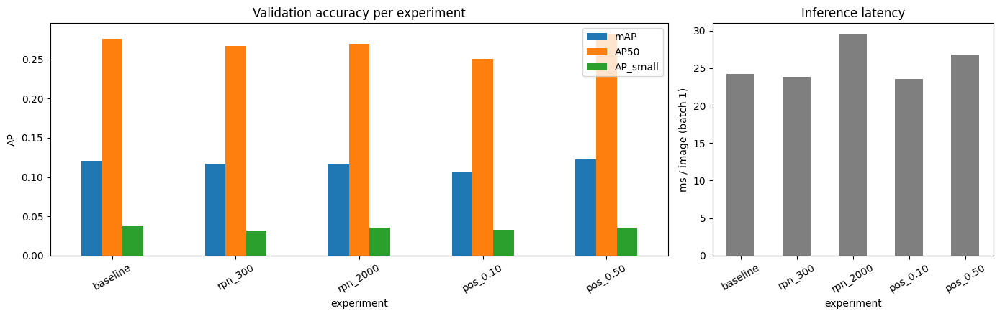

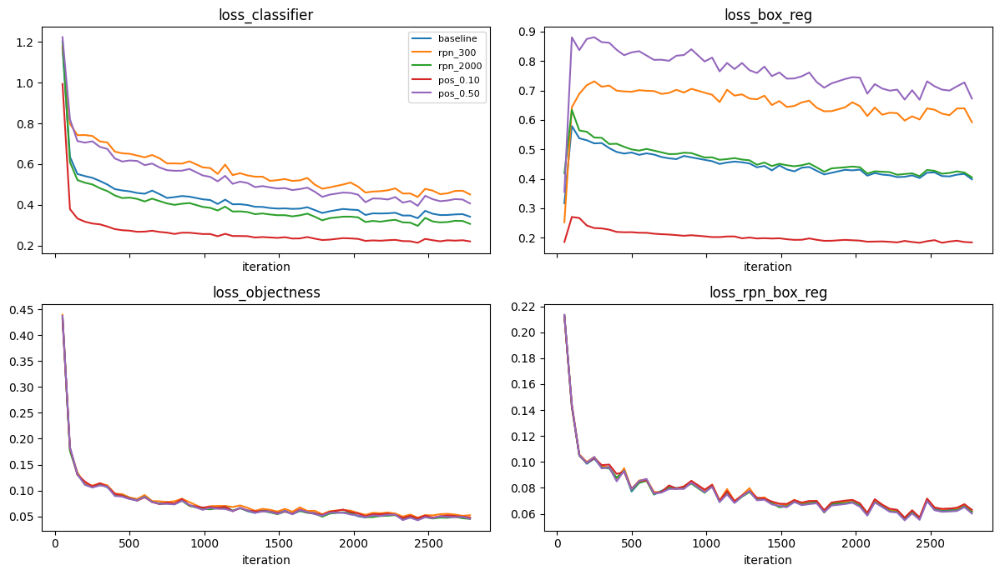

,experiment,rpn_proposals,box_positive_fraction,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_img,fps,train_min
0,baseline,1000,0.25,0.120,0.276,0.039,0.104,0.250,24.241,41.253,52.469
1,rpn_300,300,0.25,0.117,0.267,0.031,0.099,0.251,23.847,41.933,46.785
2,rpn_2000,2000,0.25,0.116,0.270,0.036,0.101,0.248,29.511,33.886,47.150
3,pos_0.10,1000,0.10,0.106,0.250,0.033,0.095,0.226,23.555,42.454,48.297
4,pos_0.50,1000,0.50,0.122,0.282,0.035,0.106,0.255,26.846,37.249,47.666


In [10]:
from scripts.eda import finish_figure

out = RUNS / "ablation"
finish_figure(R.plot_ablation(df), "ablation", out, show=True)
finish_figure(R.plot_loss_curves([out / n for n in df["experiment"]]), "loss_curves", out, show=True)
df[[c for c in R.TABLE_COLS if c in df]].round(3)

In [ ]:
run = RUNS / "ablation"
R.reevaluate_run(run / "baseline")
R.reevaluate_run(run / "rpn_300")
R.reevaluate_run(run / "rpn_2000")
R.reevaluate_run(run / "pos_0.10")
R.reevaluate_run(run / "pos_0.50")

[baseline] mAP 0.120  AP50 0.276  AP_small 0.039
[rpn_300] mAP 0.117  AP50 0.267  AP_small 0.031
[rpn_2000] mAP 0.116  AP50 0.270  AP_small 0.036
[pos_0.10] mAP 0.106  AP50 0.250  AP_small 0.033
[pos_0.50] mAP 0.122  AP50 0.282  AP_small 0.035


{'experiment': 'pos_0.50',
 'rpn_proposals': 1000,
 'box_positive_fraction': 0.5,
 'epochs': 3,
 'train_stride': 2,
 'train_min': 47.66622788906098,
 'mAP': 0.12240686030749152,
 'AP50': np.float64(0.2818594790929916),
 'AP75': np.float64(0.09343494268321306),
 'AP_small': np.float64(0.03526554787832015),
 'AP_medium': np.float64(0.10586595116607378),
 'AP_large': np.float64(0.25482962865258296),
 'AR500': np.float64(0.27231376159847603),
 'AR_small': np.float64(0.16019198759632053),
 'AP_person': 0.1373546288768989,
 'AP_bicycle': 0.028618262049255962,
 'AP_car': 0.29472926241724606,
 'AP_van': 0.1358142547144925,
 'AP_truck': 0.02910672308357927,
 'AP_tricycle': 0.056790265544340496,
 'AP_bus': 0.20862703520024078,
 'AP_motor': 0.08821445057387829,
 'ms_per_img': 26.846434911163264,
 'ms_median': 26.23970249987906,
 'fps': 37.24889369143688,
 'device': 'Tesla T4'}

In [13]:
L.describe_setup(base)

'# Training setup: Faster R-CNN\n- Model: torchvision Faster R-CNN, ResNet-50-FPN (v1), initialised from COCO weights `FasterRCNN_ResNet50_FPN_Weights.COCO_V1`; box predictor replaced by a new 9-way head (8 classes + background)\n- Anchors: sizes per FPN level ((16,), (32,), (64,), (128,), (256,)), aspect ratios (0.5, 1, 2)\n- RPN: 1000 proposals after NMS (train and test); RoI head samples 512 RoIs/image, positive fraction 0.25\n- Input: long side resized to 1536 px (aspect ratio kept); torchvision normalises with ImageNet mean/std\n- Backbone: frozen BatchNorm, last 3 ResNet stages + FPN + heads trained\n- Inference: score threshold 0.001, NMS IoU 0.5, max 500 detections/image\n- Optimiser: SGD momentum 0.9, lr 0.005, weight decay 0.0001, cosine schedule, 300 warm-up iterations, grad-clip 10.0\n- Batch size 4, 3 epochs, mixed precision: True\n- Augmentation: horizontal flip p=0.5, colour jitter 0.2 (brightness/contrast/saturation, hue/4), random zoom-in crop p=0.0 (side fraction 0.5-

### Final training

In [ ]:
BEST = {"rpn_proposals": 1000, "box_positive_fraction": 0.25}
final = replace(base, out_dir=str(RUNS / "final4"), epochs=3, train_stride=1, **BEST)
row = R.run_experiment("final", final, device)
{k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}

### Failure analysis

collecting stage outputs for 1525 validation frames ...

--- RPN: share of GT boxes with a proposal IoU>=thr (top-N proposals) ---
   n_proposals  iou_thr  recall_all  recall_<32px  recall_>=32px  mean_best_iou
0          100      0.5       0.650         0.505          0.711          0.526
1          100      0.7       0.437         0.268          0.507          0.526
2          300      0.5       0.788         0.690          0.829          0.629
3          300      0.7       0.561         0.417          0.621          0.629
4         1000      0.5       0.870         0.813          0.893          0.686
5         1000      0.7       0.653         0.539          0.701          0.686
6         2000      0.5       0.903         0.861          0.921          0.709
7         2000      0.7       0.692         0.589          0.734          0.709

--- AP with and without caring about the class (gap = cost of the classifier) ---
           class-aware  class-agnostic
mAP              0.212     

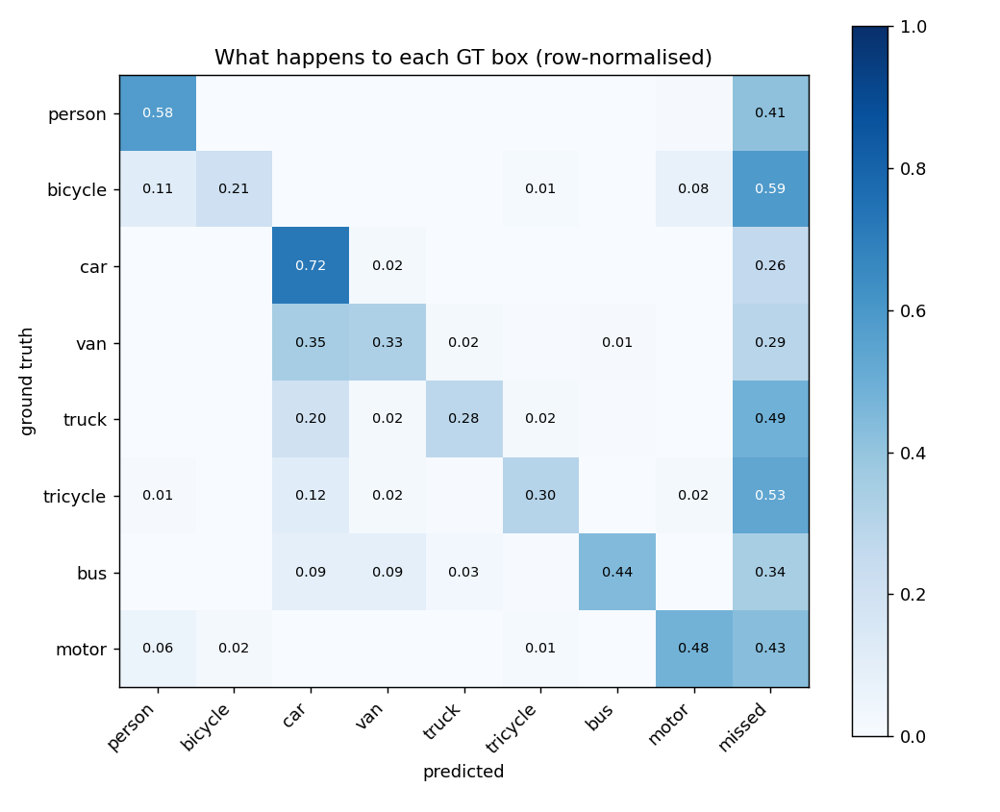

failure_cases.png


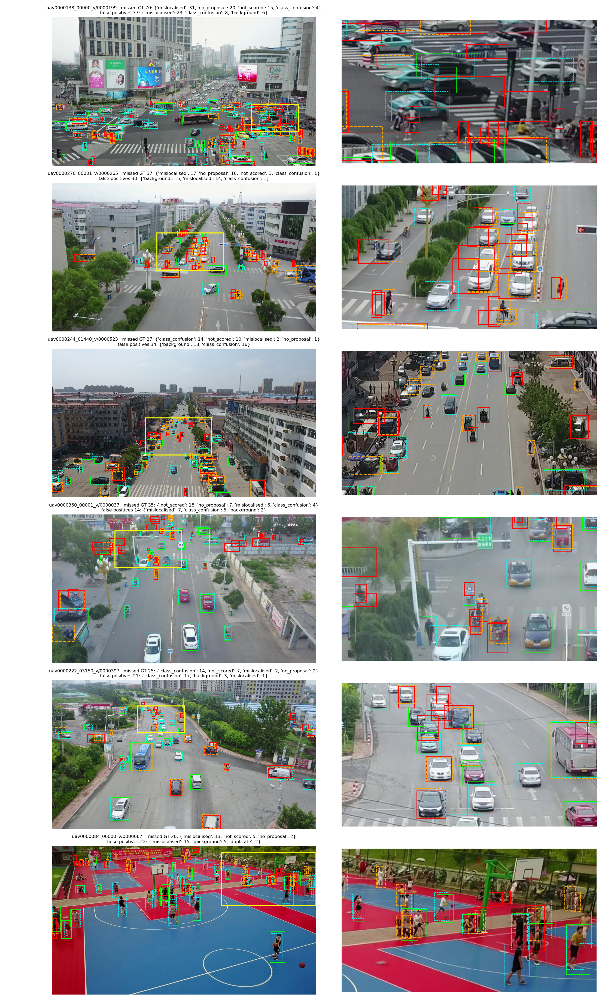

outcomes_by_class.png


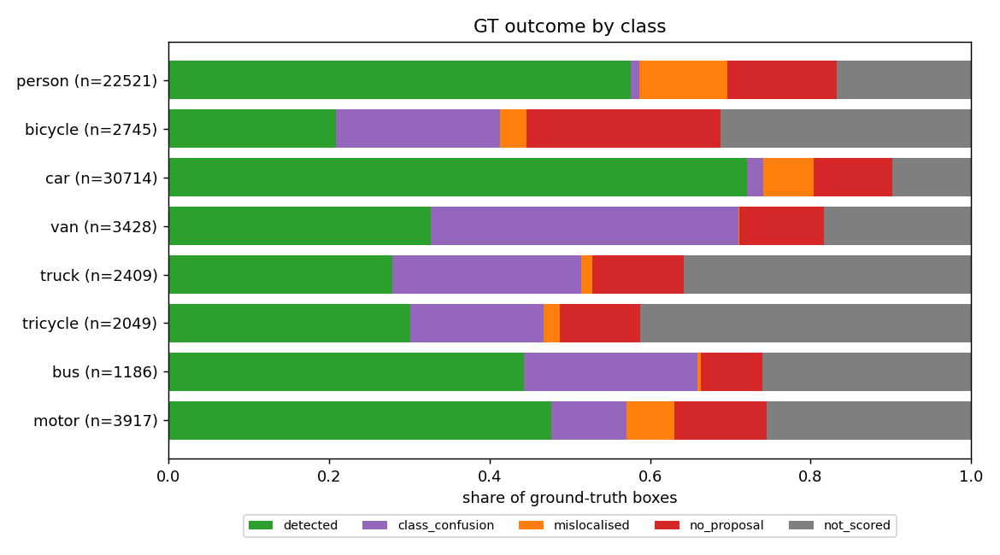

outcomes_by_clip.png


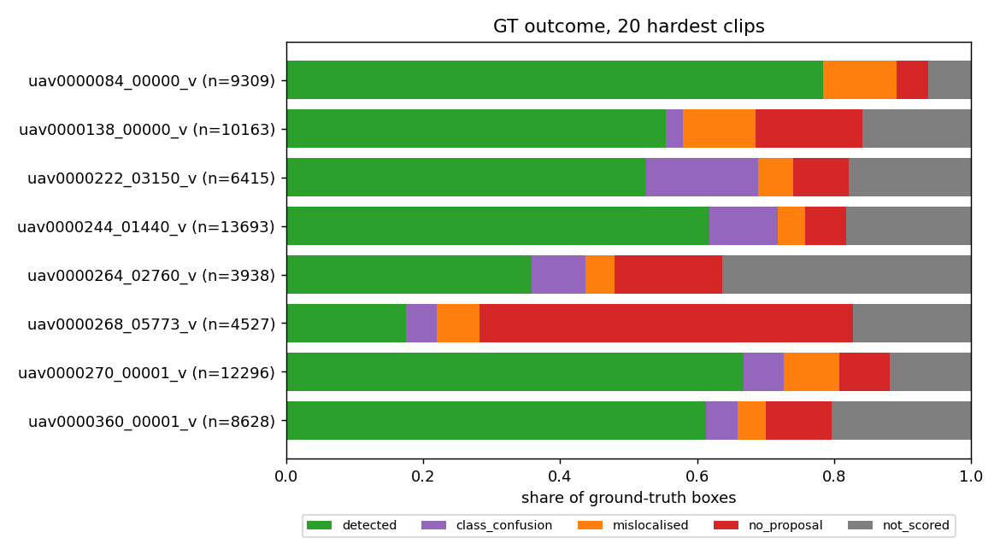

outcomes_by_size.png


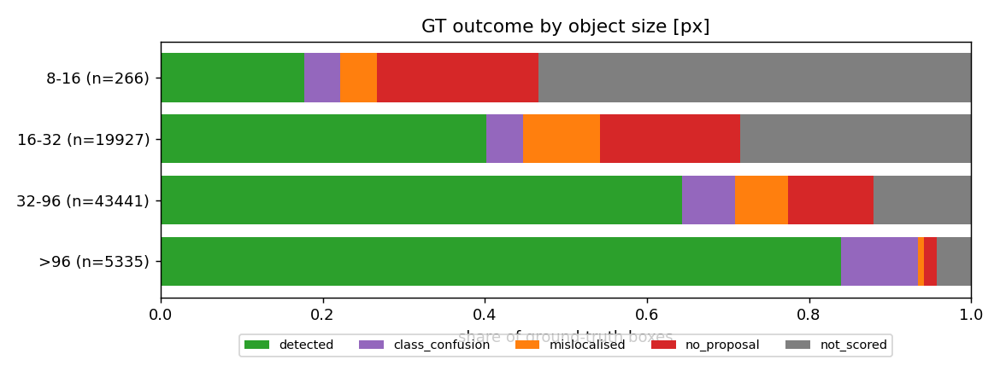

In [16]:
import scripts.analyze_model as A
from IPython.display import Image, display

run = RUNS / "final2" / "final2"
records, gt_df, det_df = A.analyze(run, score_thr=0.3, n_failures=6)
for f in sorted((run / "analysis").glob("*.png")):
    print(f.name)
    display(Image(str(f)))

We can see that the smaller the object the harder it is for model to detect and classify because the less pixels the object takes the easier it is for model to completely miss it or misclassify it. We will try fixing it by increasing the image size the model resizes frames to.

We also see a big gap between class agnostic and class avare mAP, which shows that even when model correctly detects the object, it often struggles to classify it correclty. Class confusion is the highest for vans(38.3%), trucks(23.5%) and busses(21.7%). This is due to high class imbalance, as this is much rarer for dominant classes (people and cars).

We also see that mean best proposal IoU(0.784) is higher than mean final box IoU(0.753). This probably happens because we have both very small objects, such as people and big objects, for example buses, and the model struggles to find the optimal bounding box size to fit all of those.

#### What each stage contributes:

1. Region proposal stage (RPN):

Filters out the background and detects candidate boxes for the next stage to analyse. 

2. Classification and regression:

Takes the boxes from first stage, adjusts them to fit objects and classifies the objects.

#### Checking different image sizes

In [ ]:
size_df = R.sweep_test_sizes(RUNS / "final4" / "final4", [1536, 1920])
if size_df is not None:
    display(size_df.round(3))

test size 1536: mAP 0.201  AP50 0.432  AP_small 0.086  62 ms/img
test size 1920: mAP 0.213  AP50 0.468  AP_small 0.084  123 ms/img


,test_imgsz,mAP,AP50,AP_small,AR500,ms_per_img,fps
0,1536,0.201,0.432,0.086,0.367,62.264,16.061
1,1920,0.213,0.468,0.084,0.383,122.663,8.152


#### Generating submissions

In [ ]:
import scripts.make_submission as MS

SUB_DIR = RUNS / "submissions"
paths = MS.generate_all(
    DATA_ROOT,
    runs={"faster": RUNS / "final4" / "final4"},
    out_dir=SUB_DIR, device=L.get_device(),
    test_proposals=None,
    max_images=None,
    check=True,
    test_imgsz=1920)
paths

[faster] round-trip check on validation frames
          raw detections  after formatting
mAP               0.2164            0.2163
AP50              0.4706            0.4712
AP_small          0.0908            0.0909
[faster] detecting on 3811 test images ...
[faster] wrote /content/drive/MyDrive/ai-hw2/runs/submissions/submission_faster_rcnn.csv: {'images': 3811, 'empty': 0, 'detections': 1259954, 'mean_per_image': 330.60981369719235, 'max_per_image': 500}


{'faster': PosixPath('/content/drive/MyDrive/ai-hw2/runs/submissions/submission_faster_rcnn.csv')}

In [ ]:
!kaggle competitions submit -c multiple-object-video-detection-hw-2-ucu-ai-2026 -f /content/drive/MyDrive/ai-hw2/runs/submissions/submission_ensemble.csv -m "Ensemble"

100% 58.8M/58.8M [00:01<00:00, 37.4MB/s]
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026